In [25]:
import time, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from concurrent.futures import ThreadPoolExecutor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from scipy.optimize import curve_fit

warnings.filterwarnings("ignore")
plt.rcParams["font.sans-serif"] = ["SimHei", "Arial Unicode MS"] 
plt.rcParams["axes.unicode_minus"] = False

In [26]:
CSV_PATH = "online_shoppers_intention.csv"

df = pd.read_csv(CSV_PATH)

drop_cols = [c for c in df.columns if "id" in c.lower() or "index" in c.lower()]
X = df.drop(columns=drop_cols, errors="ignore").select_dtypes(include=[np.number]).values

# 标准化
X = StandardScaler().fit_transform(X.astype(np.float64))

print(f"数据集最终形状 (样本数, 特征维度): {X.shape}")
print(f"注：已剔除 {len(drop_cols)} 个非数值/索引列，完成 Z-Score 标准化处理。")

数据集最终形状 (样本数, 特征维度): (12330, 14)
注：已剔除 0 个非数值/索引列，完成 Z-Score 标准化处理。


In [27]:
def kmeanspp_init(X, k, rng):
    """
    KMeans++ 质心初始化算法。
    核心思想：下一个质心倾向于选择距离当前所有已有质心最远的点，避免质心挤在一起。
    """
    n = X.shape[0]
    centers = [X[rng.integers(n)]]  # 随机选择第一个质心
    
    for _ in range(k - 1):
        # 计算每个样本到最近一个质心的距离平方
        distances = ((X[:, None, :] - np.array(centers)[None, :, :]) ** 2).sum(-1)
        min_dists = np.min(distances, axis=1)
        
        # 将距离转化为概率分布（距离越远，被选中的概率越大）
        probabilities = min_dists / min_dists.sum()
        
        # 按照概率分布选择下一个质心
        next_center_idx = rng.choice(n, p=probabilities)
        centers.append(X[next_center_idx])
        
    return np.array(centers, dtype=np.float64)

In [28]:
def assign_block(X_block, centers):
    """
    并行任务：计算当前数据块中的每个样本点到所有质心的距离，
    并返回该样本点归属的最近质心的索引 (argmin)。
    """
    distances = ((X_block[:, None, :] - centers[None, :, :]) ** 2).sum(-1)
    return np.argmin(distances, axis=1)

def kmeans_mt(X, k, max_iter=200, tol=1e-4, n_threads=4, seed=0):
    """
    多线程 KMeans 核心聚类算法。
    - 分配步（Assign）：将数据按线程数切块，利用 ThreadPoolExecutor 并行计算。
    - 更新步（Update）：主线程串行聚合，重新计算质心坐标。
    """
    rng = np.random.default_rng(seed)
    centers = kmeanspp_init(X, k, rng)
    n_samples = len(X)
    
    # 将数据按线程数切分为多个等大的数据块
    step = int(np.ceil(n_samples / n_threads))
    blocks = [X[i:i + step] for i in range(0, n_samples, step)]
    
    for _ in range(max_iter):
        old_centers = centers.copy()
        
        # --- 分配步 ---
        with ThreadPoolExecutor(max_workers=n_threads) as executor:
            labels_parts = list(executor.map(lambda b: assign_block(b, centers), blocks))
        
        labels = np.concatenate(labels_parts)  # 拼接所有线程的计算结果
        
        # --- 更新步（串行）---
        new_centers = np.zeros_like(centers)
        for j in range(k):
            mask = (labels == j)
            if mask.any():
                # 计算当前簇内样本的均值作为新质心
                new_centers[j] = X[mask].mean(axis=0)
            else:
                # 若某簇出现空集，则保持原质心
                new_centers[j] = old_centers[j]
                
        centers = new_centers
        
        # 判断收敛条件：质心移动距离小于容差 tol
        if np.linalg.norm(centers - old_centers) < tol:
            break
            
    return labels, centers

In [29]:
# --- 超参数定义区 ---
THREAD_GRID = [1, 2, 4, 6, 8, 12, 16, 32, 64]  # 待测试的线程数列表
K, REP = 8, 5  # 设定聚类数 K=8，每组测试重复 5 次取平均值以消除波动
# -------------------------------

results = []
print(f"正在对 {len(THREAD_GRID)} 种线程配置进行性能扫描 (K={K}, 重复次数={REP})...")
print("-" * 70)

for t in THREAD_GRID:
    times = []
    sils = []
    for rep in range(REP):
        # 记录开始时间
        start_time = time.perf_counter()
        # 运行多线程 KMeans
        labels, _ = kmeans_mt(X, K, n_threads=t, seed=rep)
        end_time = time.perf_counter()
        
        times.append(end_time - start_time)
        # 计算轮廓系数
        sils.append(silhouette_score(X, labels, sample_size=5000))
        
    mean_time = np.mean(times)
    std_time = np.std(times)
    mean_sil = np.mean(sils)
    
    results.append((t, mean_time, std_time, mean_sil))
    print(f"线程数 = {t:2d}  |  平均耗时 = {mean_time:.3f}s ±{std_time:.3f}  |  轮廓系数 = {mean_sil:.3f}")

# 转换为 DataFrame 方便后续处理
res_df = pd.DataFrame(results, columns=["threads", "time", "std", "silhouette"])

正在对 9 种线程配置进行性能扫描 (K=8, 重复次数=5)...
----------------------------------------------------------------------
线程数 =  1  |  平均耗时 = 0.369s ±0.091  |  轮廓系数 = 0.199
线程数 =  2  |  平均耗时 = 0.216s ±0.049  |  轮廓系数 = 0.198
线程数 =  4  |  平均耗时 = 0.180s ±0.036  |  轮廓系数 = 0.199
线程数 =  6  |  平均耗时 = 0.167s ±0.030  |  轮廓系数 = 0.200
线程数 =  8  |  平均耗时 = 0.169s ±0.031  |  轮廓系数 = 0.202
线程数 = 12  |  平均耗时 = 0.141s ±0.022  |  轮廓系数 = 0.199
线程数 = 16  |  平均耗时 = 0.140s ±0.022  |  轮廓系数 = 0.201
线程数 = 32  |  平均耗时 = 0.187s ±0.035  |  轮廓系数 = 0.200
线程数 = 64  |  平均耗时 = 0.307s ±0.053  |  轮廓系数 = 0.199


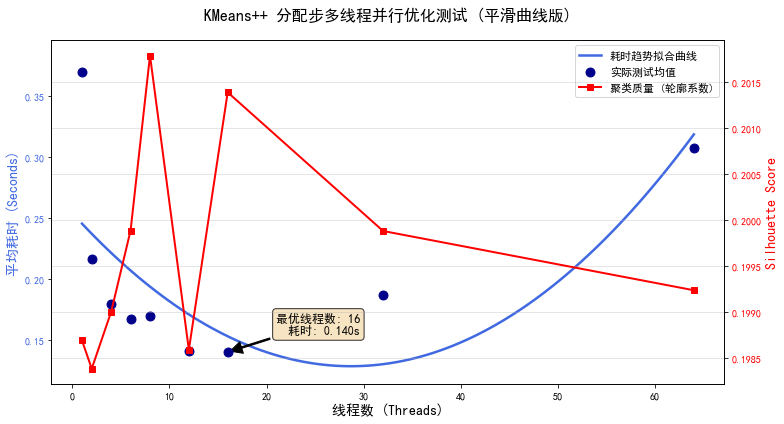


  【实验结论】
  1. 最优线程数: 16 线程
  2. 最短平均耗时: 0.140 s
  3. 相比单线程最大加速比: 2.63x


In [30]:
# 提取耗时最短的最优线程配置
best = res_df.loc[res_df["time"].idxmin()]

def quadratic(x, a, b, c):
    return a * x**2 + b * x + c

fit_x = np.linspace(min(res_df["threads"]), max(res_df["threads"]), 100)
popt, pcov = curve_fit(quadratic, res_df["threads"], res_df["time"])
fit_y = quadratic(fit_x, *popt)

fig, ax1 = plt.subplots(figsize=(11, 6))

# 绘制散点
ax1.scatter(res_df["threads"], res_df["time"], color="darkblue", zorder=5, s=80, label="实际测试均值")

# 绘制拟合后的平滑曲线 
ax1.plot(fit_x, fit_y, color="royalblue", linestyle="-", linewidth=2.5, label="耗时趋势拟合曲线")

# 设置主 Y 轴
ax1.set_xlabel("线程数 (Threads)", fontsize=14)
ax1.set_ylabel("平均耗时 (Seconds)", fontsize=14, color="royalblue")
ax1.tick_params(axis="y", labelcolor="royalblue")

# 5. 绘制红线轮廓系数
line_color = "red"
ax2 = ax1.twinx()
ax2.plot(res_df["threads"], res_df["silhouette"], color=line_color, marker="s", 
         linewidth=2, markersize=6, label="聚类质量 (轮廓系数)")
ax2.set_ylabel("Silhouette Score", fontsize=14, color=line_color)
ax2.tick_params(axis="y", labelcolor=line_color)

# 标题与网格
ax1.set_title("KMeans++ 分配步多线程并行优化测试 (平滑曲线版)", fontsize=16, fontweight='bold', pad=20)
plt.grid(True, alpha=0.4)

# 标注最优解
ax1.annotate(f'最优线程数: {int(best["threads"])}\n  耗时: {best["time"]:.3f}s', 
             xy=(best['threads'], best['time']), 
             xytext=(best['threads'] + 5, best['time'] * 1.1),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5),
             fontsize=12, bbox=dict(boxstyle="round,pad=0.3", fc="wheat", alpha=0.8))

# 合并图例
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper right", fontsize=11)

plt.tight_layout()
plt.show()

# 输出文字总结
print("\n" + "=" * 50)
print(f"  【实验结论】")
print(f"  1. 最优线程数: {int(best['threads'])} 线程")
print(f"  2. 最短平均耗时: {best['time']:.3f} s")
print(f"  3. 相比单线程最大加速比: {res_df['time'].iloc[0] / best['time']:.2f}x")
print("=" * 50)